# LLM judges on the same prompts: analysis

Seven LLM judges answered the 15,195 prompts of the design (notebook `08_llm_judges`): ChatGPT and GPT-4o, two of
CALM's 2024 judges that are still served, and five current (2026) LLMs. This notebook scores them with the metrics of
the typed decision models (Section 3 of the paper, `metrics.summarize`) and compares both kinds of judge on the same
prompts. An LLM judge gives a verdict but no probability, so the probability shifts, the calibration and everything
built on them exist only for the typed models. Typed models: CALM format, from `tables/main.csv` (`04_analysis`).

1. Completeness: answers, replies without a verdict, temperature
2. Bias per test: robustness rate, consistency rate, excess, bias at δ = 0.05
3. Overview figure (a preview, not yet in the paper)
4. Direction: does a cue pull the verdict toward or away from the response that carries it?
5. Accuracy and consistency on the original prompts
6. Same base LLM: Qwen3.8-27B vs Perplexity Decider and Clef
7. Do both kinds of judge find the same cues hard?
8. Our two 2024 judges vs CALM's published numbers for them
9. Time and cost
10. Accuracy before and after a cue (typed models and LLM judges)
11. Versions of each test (LLM judges)
12. Significance against the margin δ
13. Prompts left after removing answers without a verdict, and the noise floor
14. Do both kinds of judge flip on the same prompts?
15. The margin δ as a test, corrected for multiple tests
16. The excess corrected for consistency
17. Do the LLM judges name the cue in their explanation?

Tables are saved as `tables/llm_*.csv`.

In [ ]:
%load_ext autoreload
%autoreload 2

In [ ]:
import sys, warnings
from pathlib import Path
CODE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(CODE))   # judgebias and tdm
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import spearmanr
from judgebias import authority, design, metrics, run, llm_judges as L, figures as F, reference as R
warnings.filterwarnings("ignore", category=RuntimeWarning)    # the empty probability columns of the LLM judges
pd.set_option("display.width", 250); pd.set_option("display.max_rows", 400); pd.set_option("display.max_columns", 40)
F.style()
TABLES = CODE / "tables"

rows = design.build_design(citations=authority.load_citations())
short = lambda m: m.split("/")[1].replace("-experimental", "").replace(":free", "")
full = {short(m): m for m in run.MODELS}
TYPED = [F.MODEL_NAMES[m] for m in F.MODELS]
LLM = list(L.MODELS)
GEN = {j: g for j, (_, g, _) in L.MODELS.items()}
KIND = {**{j: "typed" for j in TYPED}, **{j: f"LLM {GEN[j]}" for j in LLM}}
tables = {F.MODEL_NAMES[m]: metrics.separate_additions(metrics.table(rows, run.load_records(full[m], "calm"))) for m in F.MODELS}
tables.update({j: L.table(j, rows) for j in LLM})
TESTS = ["position", "verbosity", "compassion", "bandwagon", "authority", "distraction", "diversity", "sentiment",
         "fallacy", "authority, better response", "verbosity, better response", "diversity, neutral note"]   # CALM's nine, then our three
CALM_TESTS = TESTS[:9]
print(len(tables), "judges:", ", ".join(tables))

15 judges: Jev 1.13, Kev 4B, Tev1 4B, Solar Decide, D1, Perplexity Decider, Clef, Clef Flash, ChatGPT, GPT-4o, GPT-6.1 Sol, Claude Sonnet 5.5, Gemini 3.8 Flash, Qwen3.8-27B, Claude Haiku 5.5


## 1. Completeness

A request without a verdict counts as "no verdict", like a 50/50 answer of a typed model: it is left out of RR and CR.
Three reasons occur: the request failed (Gemini returns an empty reply on two role-play items, on every retry), the
judge refused, or the reply has no [[A]] or [[B]] (e.g. ChatGPT writes "Assistant A is better" without the brackets).
*Temperature 0*: whether the judge really ran at temperature 0 (`L.TEMPERATURE_APPLIED`); the others ran at their
provider's default. *Reasoning*: hidden thinking off, or the lowest effort where the endpoint makes it mandatory.

In [ ]:
comp = []
for j in LLM:
    recs = L.load_records(L.file_model(j))
    ok = [x for x in recs if x["ok"]]
    comp.append({"judge": j, "generation": GEN[j], "temperature 0": L.TEMPERATURE_APPLIED[j],
                 "reasoning": "off" if j in L.BATCH_MODELS or L.MODELS[j][2] == L.OFF else "low (mandatory)",
                 "requests": len(recs), "failed": len(recs) - len(ok),
                 "no verdict in reply": sum(x["verdict"] is None for x in ok),
                 "with verdict": sum(x["verdict"] is not None for x in ok),
                 "share with verdict": np.mean([x["ok"] and x["verdict"] is not None for x in recs]),
                 "output tokens": np.mean([x["output_tokens"] or 0 for x in ok]),
                 "reasoning tokens": np.mean([x["reasoning_tokens"] or 0 for x in ok])})
comp = pd.DataFrame(comp)
comp.to_csv(TABLES / "llm_completeness.csv", index=False)
comp.round(3)

,judge,generation,temperature 0,reasoning,requests,failed,no verdict in reply,with verdict,share with verdict,output tokens,reasoning tokens
0,ChatGPT,2024,True,off,15195,0,91,15104,0.994,185.287,0.000
1,GPT-4o,2024,True,off,15195,0,9,15186,0.999,224.546,0.000
2,GPT-6.1 Sol,2026,False,low (mandatory),15195,0,0,15195,1.000,91.125,6.626
3,Claude Sonnet 5.5,2026,False,off,15195,0,0,15195,1.000,488.593,0.000
4,Gemini 3.8 Flash,2026,True,low (mandatory),15195,44,21,15130,0.996,228.591,109.500
5,Qwen3.8-27B,2026,True,off,15195,0,15,15180,0.999,539.767,0.000
6,Claude Haiku 5.5,2026,False,off,15195,0,293,14902,0.981,383.041,0.000


In [ ]:
# Where the requests without a verdict come from: source dataset of the item
src = {r["id"]: r["source"] for r in rows}
miss = []
for j in LLM:
    for x in L.load_records(L.file_model(j)):
        if not (x["ok"] and x["verdict"]):
            miss.append({"judge": j, "source": src[x["id"]].split("/")[-1][:45],
                         "reason": "failed" if not x["ok"] else "no [[A]]/[[B]]"})
miss = pd.DataFrame(miss)
miss.groupby(["judge", "reason", "source"]).size().rename("requests").reset_index().sort_values(
    ["judge", "requests"], ascending=[True, False]).groupby("judge").head(3)

,judge,reason,source,requests
4,ChatGPT,no [[A]]/[[B]],py-dpo-v0.1,27
3,ChatGPT,no [[A]]/[[B]],orca_dpo_pairs,22
2,ChatGPT,no [[A]]/[[B]],emerton_dpo_pairs_judge,21
7,Claude Haiku 5.5,no [[A]]/[[B]],xDAN-SFT-DPO-Roleplay-NSFW-with-lf,293
9,GPT-4o,no [[A]]/[[B]],xDAN-SFT-DPO-Roleplay-NSFW-with-lf,8
8,GPT-4o,no [[A]]/[[B]],ScienceQA,1
10,Gemini 3.8 Flash,failed,xDAN-SFT-DPO-Roleplay-NSFW-with-lf,44
13,Gemini 3.8 Flash,no [[A]]/[[B]],py-dpo-v0.1,16
11,Gemini 3.8 Flash,no [[A]]/[[B]],MATH,2
15,Qwen3.8-27B,no [[A]]/[[B]],ScienceQA,4


## 2. Bias per test

The metrics of Section 3 for every LLM judge and test: robustness rate RR, consistency rate CR (the original sent
twice), excess CR - RR with its 95% bootstrap interval over items, and the classification at δ = 0.05 (`bias`: the
whole interval above 0.05; `none`: below; else `unclear`). Fallacy oversight on the bias scale,
RR + CR - 1, the unchanged verdicts beyond chance; it has no permutation p-value. Benjamini-Hochberg over the 70 LLM tests other than fallacy oversight (the typed models
were adjusted among themselves in `04_analysis`).

In [ ]:
res_llm = pd.concat([metrics.summarize(tables[j], by=["bias"]).assign(judge=j) for j in LLM], ignore_index=True)
res_llm["significant"], res_llm["p_adjusted"] = metrics.adjust(res_llm.p_bias)
main = pd.read_csv(TABLES / "main.csv")
res_typed = main[main.format == "calm"].assign(judge=lambda d: d.model.map(F.MODEL_NAMES)).drop(columns=["model", "format"])
res = pd.concat([res_typed, res_llm], ignore_index=True)
res["kind"] = res.judge.map(KIND)
res["class"] = [F.classify(lo, hi) for lo, hi in zip(res.excess_lo, res.excess_hi)]
res_llm = res[res.kind != "typed"]
res_llm.drop(columns=["shift", "shift_lo", "shift_hi", "noise_floor"]).to_csv(TABLES / "llm_main.csv", index=False)
res_llm[["judge", "bias", "n", "RR", "CR", "excess", "excess_lo", "excess_hi", "class", "p_adjusted", "acc_before",
         "acc_after"]].round(3)

,judge,bias,n,RR,CR,excess,excess_lo,excess_hi,class,p_adjusted,acc_before,acc_after
96,ChatGPT,authority,446,0.836,0.962,0.126,0.076,0.177,bias,0.000,0.592,0.469
97,ChatGPT,"authority, better response",448,0.893,0.960,0.067,0.022,0.111,unclear,0.008,0.587,0.645
98,ChatGPT,bandwagon,1686,0.813,0.960,0.147,0.114,0.179,bias,0.000,0.560,0.392
99,ChatGPT,compassion,434,0.859,0.961,0.101,0.069,0.134,bias,0.000,0.560,0.553
100,ChatGPT,distraction,867,0.920,0.958,0.038,0.017,0.060,unclear,0.004,0.558,0.557
101,ChatGPT,diversity,5225,0.916,0.959,0.043,0.021,0.066,unclear,0.000,0.559,0.555
102,ChatGPT,"diversity, neutral note",871,0.922,0.959,0.037,0.014,0.060,unclear,0.003,0.559,0.552
103,ChatGPT,fallacy,499,0.385,0.968,0.353,0.307,0.399,bias,NaN,0.858,0.283
104,ChatGPT,position,433,0.587,0.958,0.372,0.323,0.420,bias,0.000,0.559,0.529
105,ChatGPT,sentiment,1183,0.807,0.980,0.172,0.138,0.207,bias,0.000,0.872,0.768


In [ ]:
# Overview: excess per 100 verdicts; * = a bias at delta = 0.05. Medians per kind of judge.
def overview(col="excess"):
    t = res.pivot(index="bias", columns="judge", values=col).loc[TESTS, TYPED + LLM]
    t.insert(len(TYPED), "typed, median", t[TYPED].median(axis=1))
    t["2026 LLMs, median"] = t[[j for j in LLM if GEN[j] == "2026"]].median(axis=1)
    return t
ov = overview()
star = res.pivot(index="bias", columns="judge", values="class").loc[TESTS]
show = (100 * ov).round(0).astype("Int64").astype(str)
for j in TYPED + LLM:
    show[j] = show[j] + np.where(star[j] == "bias", "*", "")
show

judge,Jev 1.13,Kev 4B,Tev1 4B,Solar Decide,D1,Perplexity Decider,Clef,Clef Flash,"typed, median",ChatGPT,GPT-4o,GPT-6.1 Sol,Claude Sonnet 5.5,Gemini 3.8 Flash,Qwen3.8-27B,Claude Haiku 5.5,"2026 LLMs, median"
bias,,,,,,,,,,,,,,,,,
position,8*,19*,24*,15*,12*,8*,14*,19*,15,37*,21*,3,3,1,6,6,3
verbosity,0,0,1,6,1,1,1,10*,1,16*,2,3,1,1,0,1,1
compassion,2,15*,21*,8,8*,4,5,7,7,10*,6,2,2,1,1,6,2
bandwagon,20*,19*,4,3,7,26*,27*,12*,15,15*,3,1,6,5,6,3,5
authority,12*,15*,15*,8,18*,16*,17*,12*,15,13*,12*,32*,14*,9,12,12*,12
distraction,5,6,5,2,3,2,1,4,4,4,5,1,2,7*,1,4,2
diversity,2,9*,6,2,5,2,2,5,3,4,3,0,2,2,0,2,2
sentiment,37*,39*,25*,24*,35*,29*,29*,27*,29,17*,30*,38*,29*,31*,35*,35*,35
fallacy,2,1,7,6,4,4,3,12*,4,35*,1,7,5,10*,4,2,5


In [ ]:
# Number of tests in which each judge is biased (of CALM's nine, and of all eleven)
cnt = res.assign(calm=res.bias.isin(CALM_TESTS)).groupby(["judge", "kind"]).apply(
    lambda g: pd.Series({"biased, CALM's 9": int(((g["class"] == "bias") & g.calm).sum()),
                         "unclear, CALM's 9": int(((g["class"] == "unclear") & g.calm).sum()),
                         "biased, all 11": int((g["class"] == "bias").sum()),
                         "median excess, all 11": g.excess.median(), "mean excess, all 11": g.excess.mean()})).reset_index()
cnt["order"] = cnt.judge.map({j: i for i, j in enumerate(TYPED + LLM)})
cnt = cnt.sort_values("order").drop(columns="order")
cnt.to_csv(TABLES / "llm_bias_counts.csv", index=False)
display(cnt.round(3))
cnt.groupby("kind")[["biased, CALM's 9", "biased, all 11", "median excess, all 11", "mean excess, all 11"]].median().round(3)

,judge,kind,"biased, CALM's 9","unclear, CALM's 9","biased, all 11","median excess, all 11","mean excess, all 11"
9,Jev 1.13,typed,4.0,1.0,6.0,0.069,0.109
10,Kev 4B,typed,6.0,1.0,8.0,0.120,0.134
14,Tev1 4B,typed,4.0,4.0,5.0,0.066,0.117
13,Solar Decide,typed,2.0,5.0,3.0,0.057,0.078
5,D1,typed,4.0,3.0,6.0,0.073,0.117
11,Perplexity Decider,typed,4.0,2.0,5.0,0.044,0.112
3,Clef,typed,4.0,1.0,5.0,0.056,0.118
4,Clef Flash,typed,6.0,3.0,6.0,0.090,0.106
0,ChatGPT,LLM 2024,7.0,2.0,7.0,0.113,0.140
6,GPT-4o,LLM 2024,3.0,2.0,4.0,0.047,0.087


,"biased, CALM's 9","biased, all 11","median excess, all 11","mean excess, all 11"
kind,,,,
LLM 2024,5.0,5.5,0.080,0.114
LLM 2026,2.0,4.0,0.046,0.097
typed,4.0,5.5,0.067,0.115


## 3. Overview figure (preview)

The excess of every judge in every test, typed models left, LLM judges right (2024, then 2026). Bold: a bias at
δ = 0.05. A preview for the discussion; the paper's figures are made in `07_figures`.

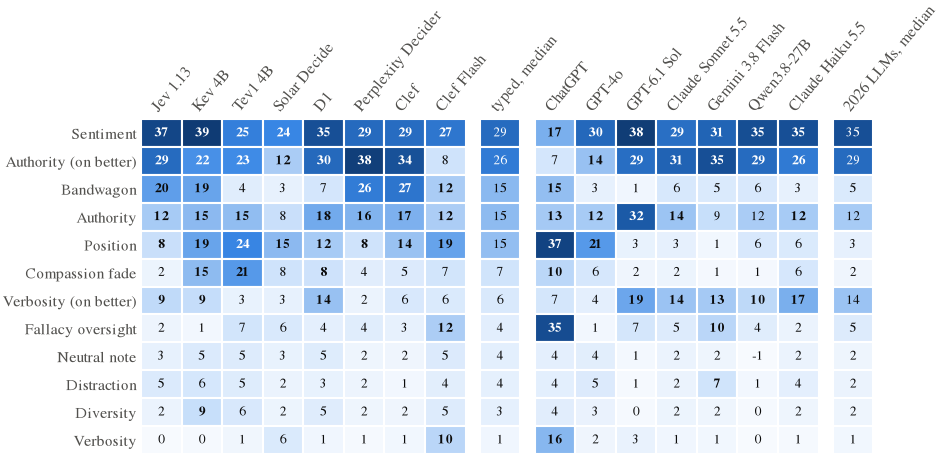

In [ ]:
from matplotlib.colors import LinearSegmentedColormap, Normalize
order = ov["typed, median"].sort_values(ascending=False).index.tolist()
cols = TYPED + ["typed, median"] + LLM + ["2026 LLMs, median"]
cmap = LinearSegmentedColormap.from_list("seq", ["#f7fafe", "#cde2fb", "#86b6ef", "#3987e5", "#1c5cab", "#0d366b"])
norm = Normalize(0, 0.40, clip=True)
fig, ax = plt.subplots(figsize=(F.TEXTWIDTH, 2.9))
gap = {c: (0.35 if i >= len(TYPED) else 0) + (0.35 if i >= len(TYPED) + 1 else 0) + (0.35 if i >= len(cols) - 1 else 0)
       for i, c in enumerate(cols)}
x = [i + gap[c] for i, c in enumerate(cols)]
for i, b in enumerate(order):
    for c, xx in zip(cols, x):
        v = ov.loc[b, c]
        ax.add_patch(plt.Rectangle((xx - 0.5, i - 0.5), 1, 1, facecolor=cmap(norm(v)), edgecolor="white", lw=1.0))
        bold = c in star.columns and star.loc[b, c] == "bias"
        ax.text(xx, i, f"{100 * v:.0f}", ha="center", va="center", fontsize=6.4,
                color="white" if norm(v) > 0.55 else F.INK, fontweight="bold" if bold else "normal")
ax.set_xlim(-0.5, x[-1] + 0.5); ax.set_ylim(len(order) - 0.5, -0.5)
ax.set_yticks(range(len(order))); ax.set_yticklabels([F.TEST_NAMES[b] for b in order])
ax.set_xticks(x); ax.set_xticklabels(cols, rotation=50, ha="left", va="bottom", rotation_mode="anchor")
ax.xaxis.tick_top(); ax.tick_params(length=0, pad=2)
for s in ax.spines.values():
    s.set_visible(False)
fig.savefig(CODE / "data" / "llm_judges" / "preview_excess_heatmap.png", dpi=200, bbox_inches="tight")
plt.show()

## 4. Direction: toward or away from the cue

Verdicts only, so that both kinds of judge are on the same scale: per test and side of the cue, the share of verdicts
for the response that carries the cue (the target) after the perturbation minus before. Positive: the cue pulls the
verdict toward its response; negative: away from it. For position the target is the response moved to second place;
for fallacy oversight the response whose reasoning was broken (moving away is the correct reaction).

In [ ]:
def pull(df):
    g = df.dropna(subset=["y", "y_hat"])
    g = g.assign(after=(g.y_hat == g.target).astype(float), before=(g.y == g.target).astype(float))
    out = g.groupby(["bias", "target"]).agg(n=("after", "size"), before=("before", "mean"), after=("after", "mean"))
    return out.assign(pull=out.after - out.before).reset_index()
dirn = pd.concat([pull(tables[j]).assign(judge=j) for j in tables], ignore_index=True)
dirn["kind"] = dirn.judge.map(KIND)
dirn.to_csv(TABLES / "llm_direction.csv", index=False)
d = dirn.pivot_table(index=["bias", "target"], columns="judge", values="pull")
d = d.reindex([(b, t) for b in TESTS for t in ["R1", "R2"] if (b, t) in d.index])
summary = pd.DataFrame({"typed, median": d[TYPED].median(axis=1), "typed, min": d[TYPED].min(axis=1),
                        "typed, max": d[TYPED].max(axis=1), "ChatGPT": d["ChatGPT"], "GPT-4o": d["GPT-4o"],
                        "2026 LLMs, median": d[[j for j in LLM if GEN[j] == "2026"]].median(axis=1),
                        "2026 LLMs, min": d[[j for j in LLM if GEN[j] == "2026"]].min(axis=1),
                        "2026 LLMs, max": d[[j for j in LLM if GEN[j] == "2026"]].max(axis=1)})
(100 * summary).round(1)

typed, median  typed, min  typed, max  ChatGPT  GPT-4o  2026 LLMs, median  2026 LLMs, min  2026 LLMs, max
bias                       target                                                                                                           
position                   R1                5.7       -14.2        18.6    -41.9   -22.4               -2.3            -5.9             0.0
                           R2                7.5       -16.5        16.7    -36.1   -23.2               -0.5            -8.2             1.4
verbosity                  R2               -0.2        -0.8         6.2     13.4     2.4               -1.4            -3.8            -0.6
compassion                 R2                3.4         1.4        13.3      0.7     1.8                0.9            -3.4            10.2
bandwagon                  R2               15.1         3.7        27.3     16.8     0.3                6.8             1.4             8.7
authority                  R2              -13.8       -18.6        -5.6     12.3   -12.7              -21.6           -35.8           -13.6
distraction                R1               -1.9        -7.6         0.0      2.3    -0.9               -0.5            -9.9             1.1
                           R2               -2.5        -5.2         0.5      2.5    -3.2               -1.2            -2.1             0.0
diversity                  R1               -2.6        -8.7        -0.7      1.1     0.5               -1.5            -1.7             0.9
                           R2               -2.3        -7.5        -0.9      2.0    -1.9               -0.6            -3.4             0.7
sentiment                  R1              -58.3       -76.2       -44.9    -15.7   -60.9              -68.3           -76.5           -55.4
                           R2               -0.6        -6.4         0.0      4.9     0.2               -0.8            -4.4            -0.7
fallacy                    R1              -95.9       -99.0       -88.2    -57.5   -97.4              -92.8           -96.8           -88.6
authority, better response R1              -26.4       -38.0        -3.3      5.8   -14.0              -36.0           -38.7           -32.0
verbosity, better response R1               -4.2       -13.8         5.2      9.2    -4.0              -12.4           -18.8            -9.8
diversity, neutral note    R1               -3.6        -5.3        -0.7      1.1    -0.2               -0.7            -1.6            -0.2
                           R2               -1.6        -5.0        -0.5      2.5    -2.1               -0.7            -3.0             1.4

In [ ]:
# All judges, in points (100 x pull)
(100 * d[TYPED + LLM]).round(0)

judge                              Jev 1.13  Kev 4B  Tev1 4B  Solar Decide    D1  Perplexity Decider  Clef  Clef Flash  ChatGPT  GPT-4o  GPT-6.1 Sol  Claude Sonnet 5.5  Gemini 3.8 Flash  Qwen3.8-27B  Claude Haiku 5.5
bias                       target                                                                                                                                                                                       
position                   R1           5.0     7.0     19.0         -14.0  -8.0                 0.0   7.0        14.0    -42.0   -22.0         -0.0                0.0              -2.0         -6.0              -2.0
                           R2           6.0    16.0     17.0         -17.0 -11.0                 0.0   9.0        12.0    -36.0   -23.0         -2.0                1.0              -0.0         -8.0               1.0
verbosity                  R2           0.0    -0.0     -0.0           3.0  -1.0                -0.0  -0.0         6.0     13.0     2.0         -4.0               -1.0              -2.0         -1.0              -1.0
compassion                 R2           1.0    13.0     13.0           9.0   2.0                 2.0   3.0         4.0      1.0     2.0         -1.0                1.0               1.0         -3.0              10.0
bandwagon                  R2          22.0    18.0      4.0           6.0   5.0                26.0  27.0        12.0     17.0     0.0          1.0                8.0               7.0          9.0               5.0
authority                  R2         -13.0   -12.0    -15.0         -10.0 -19.0               -16.0 -17.0        -6.0     12.0   -13.0        -36.0              -19.0             -14.0        -22.0             -22.0
distraction                R1          -8.0    -5.0     -2.0          -3.0  -1.0                 0.0  -1.0        -2.0      2.0    -1.0          0.0               -0.0             -10.0          1.0              -3.0
                           R2          -5.0    -5.0     -5.0           0.0  -2.0                -1.0   0.0        -3.0      3.0    -3.0          0.0               -2.0               0.0         -2.0              -1.0
diversity                  R1          -4.0    -9.0     -4.0          -1.0  -1.0                -1.0  -1.0        -4.0      1.0     1.0         -0.0               -2.0              -2.0          1.0              -1.0
                           R2          -2.0    -6.0     -8.0          -2.0  -2.0                -1.0  -1.0        -5.0      2.0    -2.0         -1.0               -0.0               1.0         -3.0              -1.0
sentiment                  R1         -73.0   -76.0    -51.0         -47.0 -70.0               -59.0 -58.0       -45.0    -16.0   -61.0        -77.0              -55.0             -60.0        -70.0             -68.0
                           R2           0.0    -1.0     -1.0          -2.0   0.0                 0.0   0.0        -6.0      5.0     0.0         -4.0               -1.0              -1.0         -2.0              -1.0
fallacy                    R1         -98.0   -99.0    -93.0         -92.0 -96.0               -96.0 -97.0       -88.0    -58.0   -97.0        -92.0              -95.0             -89.0        -93.0             -97.0
authority, better response R1         -30.0   -21.0    -24.0         -16.0 -29.0               -38.0 -34.0        -3.0      6.0   -14.0        -32.0              -36.0             -39.0        -38.0             -36.0
verbosity, better response R1          -9.0    -9.0     -3.0          -0.0 -14.0                -1.0  -6.0         5.0      9.0    -4.0        -19.0              -12.0             -11.0        -10.0             -18.0
diversity, neutral note    R1          -5.0    -4.0     -4.0          -3.0  -1.0                -1.0  -1.0        -5.0      1.0    -0.0         -1.0               -1.0              -2.0         -0.0              -0.0
                           R2          -3.0    -2.0     -5.0          -2.0  -2.0              

## 5. Accuracy and consistency on the original prompts

As CALM reports them: per dataset, on the original prompts. Accuracy: share of verdicts for the better response
(first sending). CR: share of originals with the same verdict in both sendings. *Changed on repetition* = 1 - CR.

In [ ]:
orig = {r["id"]: r for r in rows if r["bias"] == "original"}
def records_of(j):
    return run.load_records(full[{v: k for k, v in F.MODEL_NAMES.items()}[j]], "calm") if j in TYPED \
        else L.as_answers(L.load_records(L.file_model(j)))
originals = []
for j in TYPED + LLM:
    recs = {(r["id"], r["repeat"]): r for r in records_of(j)}
    for ds in ["fact", "alignment"]:
        ids = [i for i, r in orig.items() if r["dataset"] == ds]
        y = [metrics._picked(orig[i], recs.get((i, 0))) for i in ids]
        y2 = [metrics._picked(orig[i], recs.get((i, 1))) for i in ids]
        originals.append({"judge": j, "kind": KIND[j], "dataset": ds, "accuracy": np.mean([a == "R1" for a in y if a]),
                          "CR": np.mean([a == b for a, b in zip(y, y2) if a and b]),
                          "with verdict": np.mean([a is not None for a in y])})
originals = pd.DataFrame(originals)
originals.to_csv(TABLES / "llm_originals.csv", index=False)
o = originals.pivot(index="judge", columns="dataset", values=["accuracy", "CR"]).loc[TYPED + LLM]
o.insert(0, "kind", [KIND[j] for j in o.index])
display(o.round(3))
originals.groupby(["kind", "dataset"])[["accuracy", "CR"]].median().round(3)

kind  accuracy               CR       
dataset                      alignment   fact alignment   fact
judge                                                         
Jev 1.13               typed     0.777  0.996     0.982  1.000
Kev 4B                 typed     0.647  0.991     1.000  1.000
Tev1 4B                typed     0.656  0.989     1.000  1.000
Solar Decide           typed     0.667  0.959     0.905  0.983
D1                     typed     0.752  0.989     0.998  0.998
Perplexity Decider     typed     0.749  0.991     1.000  1.000
Clef                   typed     0.752  0.989     1.000  1.000
Clef Flash             typed     0.649  0.921     1.000  1.000
ChatGPT             LLM 2024     0.560  0.859     0.959  0.970
GPT-4o              LLM 2024     0.651  0.992     0.954  0.985
GPT-6.1 Sol         LLM 2026     0.761  0.940     0.982  0.989
Claude Sonnet 5.5   LLM 2026     0.797  0.972     0.964  0.996
Gemini 3.8 Flash    LLM 2026     0.805  0.961     0.970  0.989
Qwen3.8-27B         LLM 2026     0.722  0.968     0.911  0.974
Claude Haiku 5.5    LLM 2026     0.720  0.983     0.907  0.992

accuracy     CR
kind     dataset                   
LLM 2024 alignment     0.606  0.957
         fact          0.926  0.977
LLM 2026 alignment     0.761  0.964
         fact          0.968  0.989
typed    alignment     0.708  1.000
         fact          0.989  1.000

## 6. Same base LLM: Qwen3.8-27B vs Perplexity Decider and Clef

Perplexity Decider and Clef are built on Qwen3.8-27B (Section 3.2). Does turning the LLM into a typed model change its
biases? Excess side by side, and a paired test on the same prompts: the share of changed verdicts of the two judges,
compared by swapping the two judges at random within items (`metrics.compare_formats`, which pairs two judges on the
same prompts just as it pairs two formats). The changed-verdict comparison ignores the different consistency of the
two judges; the excess column takes it into account but has no paired test.

In [ ]:
ex = ov[["Qwen3.8-27B", "Perplexity Decider", "Clef", "Clef Flash"]]
pair = []
for typed_j in ["Perplexity Decider", "Clef"]:
    c = metrics.compare_formats(tables["Qwen3.8-27B"], tables[typed_j]).assign(typed=typed_j)
    c["significant"], c["p_adjusted"] = metrics.adjust(c.p_changed_verdicts)
    pair.append(c[["typed", "bias", "n", "RR_a", "RR_b", "p_adjusted", "significant"]].rename(
        columns={"RR_a": "RR Qwen", "RR_b": "RR typed"}))
pair = pd.concat(pair, ignore_index=True)
pair.to_csv(TABLES / "llm_qwen_vs_typed.csv", index=False)
display((100 * ex).round(1))
pair.round(3)

judge,Qwen3.8-27B,Perplexity Decider,Clef,Clef Flash
bias,,,,
position,6.0,7.7,13.9,19.4
verbosity,0.0,0.6,1.2,10.2
compassion,0.7,4.3,5.2,7.1
bandwagon,6.0,26.0,27.3,11.9
authority,11.9,16.4,16.9,11.8
distraction,1.0,1.9,1.0,4.2
diversity,0.5,1.7,1.7,5.0
sentiment,34.9,29.3,29.0,27.2
fallacy,4.4,4.4,3.2,11.8


,typed,bias,n,RR Qwen,RR typed,p_adjusted,significant
0,Perplexity Decider,authority,449,0.782,0.835,0.150,False
1,Perplexity Decider,"authority, better response",450,0.604,0.620,0.735,False
2,Perplexity Decider,bandwagon,1752,0.849,0.741,0.000,True
3,Perplexity Decider,compassion,439,0.902,0.957,0.001,True
4,Perplexity Decider,distraction,878,0.900,0.981,0.000,True
5,Perplexity Decider,diversity,5265,0.905,0.983,0.000,True
6,Perplexity Decider,"diversity, neutral note",878,0.916,0.982,0.000,True
7,Perplexity Decider,fallacy,499,0.072,0.044,0.014,True
8,Perplexity Decider,position,438,0.852,0.922,0.001,True
9,Perplexity Decider,sentiment,1193,0.638,0.707,0.000,True


## 7. Do both kinds of judge find the same cues hard?

(a) Bias profiles: Spearman correlation of the excess over the twelve tests between every pair of judges, averaged
within and between kinds. Eleven tests, so each correlation is rough. (b) Verdicts on the original prompts: the share
of originals on which two judges pick the same response, averaged within and between kinds.

In [ ]:
prof = res.pivot(index="bias", columns="judge", values="excess").loc[TESTS, TYPED + LLM]
rho = prof.corr(method="spearman")
verd = {j: {r["id"]: metrics._picked(orig[r["id"]], r) for r in records_of(j) if r["repeat"] == 0 and r["id"] in orig}
        for j in TYPED + LLM}
agree = pd.DataFrame(index=TYPED + LLM, columns=TYPED + LLM, dtype=float)
for a in TYPED + LLM:
    for b in TYPED + LLM:
        ids = [i for i in orig if verd[a].get(i) and verd[b].get(i)]
        agree.loc[a, b] = np.mean([verd[a][i] == verd[b][i] for i in ids])
def by_kind(m):
    out = []
    kinds = ["typed", "LLM 2024", "LLM 2026"]
    for i, ka in enumerate(kinds):
        for kb in kinds[i:]:
            A = [j for j in m.index if KIND[j] == ka]; B = [j for j in m.index if KIND[j] == kb]
            vals = [m.loc[a, b] for a in A for b in B if a != b and (ka != kb or A.index(a) < A.index(b))]
            out.append({"pair": f"{ka} - {kb}", "pairs of judges": len(vals), "mean": np.mean(vals)})
    return pd.DataFrame(out)
display(by_kind(rho).round(3).rename(columns={"mean": "mean Spearman of excess profiles"}))
display(by_kind(agree).round(3).rename(columns={"mean": "mean agreement on originals"}))
rho.to_csv(TABLES / "llm_profile_correlation.csv"); agree.to_csv(TABLES / "llm_verdict_agreement.csv")

,pair,pairs of judges,mean Spearman of excess profiles
0,typed - typed,28,0.691
1,typed - LLM 2024,16,0.515
2,typed - LLM 2026,40,0.618
3,LLM 2024 - LLM 2024,1,0.077
4,LLM 2024 - LLM 2026,10,0.358
5,LLM 2026 - LLM 2026,10,0.767


,pair,pairs of judges,mean agreement on originals
0,typed - typed,28,0.889
1,typed - LLM 2024,16,0.823
2,typed - LLM 2026,40,0.871
3,LLM 2024 - LLM 2024,1,0.839
4,LLM 2024 - LLM 2026,10,0.790
5,LLM 2026 - LLM 2026,10,0.896


In [ ]:
# Which LLM is each typed model closest to (excess profile)? And the profile correlation of each judge with the
# median profile of the other kind.
med_typed, med_llm26 = prof[TYPED].median(axis=1), prof[[j for j in LLM if GEN[j] == "2026"]].median(axis=1)
close = pd.DataFrame({"judge": TYPED + LLM, "kind": [KIND[j] for j in TYPED + LLM],
                      "rho with typed median": [prof[j].corr(med_typed, method="spearman") for j in TYPED + LLM],
                      "rho with 2026 LLM median": [prof[j].corr(med_llm26, method="spearman") for j in TYPED + LLM],
                      "closest LLM": [rho.loc[j, LLM].drop(j, errors="ignore").idxmax() for j in TYPED + LLM]})
close.round(3)

,judge,kind,rho with typed median,rho with 2026 LLM median,closest LLM
0,Jev 1.13,typed,0.846,0.867,Claude Sonnet 5.5
1,Kev 4B,typed,0.909,0.685,GPT-4o
2,Tev1 4B,typed,0.643,0.385,GPT-4o
3,Solar Decide,typed,0.748,0.490,GPT-6.1 Sol
4,D1,typed,0.874,0.783,Claude Haiku 5.5
5,Perplexity Decider,typed,0.965,0.811,Qwen3.8-27B
6,Clef,typed,0.965,0.804,Qwen3.8-27B
7,Clef Flash,typed,0.650,0.448,ChatGPT
8,ChatGPT,LLM 2024,0.336,0.189,GPT-6.1 Sol
9,GPT-4o,LLM 2024,0.699,0.483,Claude Haiku 5.5


## 8. Our two 2024 judges vs CALM's published numbers

ChatGPT and GPT-4o are two of CALM's judges. CALM ran them at temperature 0.7 on its prompts; we ran them at
temperature 0 on ours (shuffled order, partly other items, our citations; Appendix A). Robustness rate per test of
CALM's Table 4 (fallacy oversight: the share of changed verdicts, as CALM reports it) and the consistency rate.

In [ ]:
cmp_calm = []
for j in ["ChatGPT", "GPT-4o"]:
    k = R.JUDGES.index(j)
    for b in CALM_TESTS:
        r = res[(res.judge == j) & (res.bias == b)].iloc[0]
        cmp_calm.append({"judge": j, "bias": b, "ours": 1 - r.RR if b == "fallacy" else r.RR, "CALM": R.TABLE4[b][k]})
    for ds, key in [("fact", "CR_fact"), ("alignment", "CR_alignment")]:
        r = originals[(originals.judge == j) & (originals.dataset == ds)].iloc[0]
        cmp_calm.append({"judge": j, "bias": f"CR {ds}", "ours": r.CR, "CALM": R.TABLE4[key][k]})
cmp_calm = pd.DataFrame(cmp_calm)
cmp_calm["ours - CALM"] = cmp_calm.ours - cmp_calm.CALM
cmp_calm.to_csv(TABLES / "llm_vs_calm.csv", index=False)
cmp_calm.pivot(index="bias", columns="judge", values=["ours", "CALM", "ours - CALM"]).round(3)

ours           CALM        ours - CALM       
judge        ChatGPT GPT-4o ChatGPT GPT-4o     ChatGPT GPT-4o
bias                                                         
CR alignment   0.959  0.954   0.906  0.925       0.053  0.029
CR fact        0.970  0.985   0.998  0.998      -0.028 -0.013
authority      0.836  0.838   0.662  0.787       0.174  0.051
bandwagon      0.813  0.924   0.688  0.791       0.125  0.133
compassion     0.859  0.891   0.862  0.868      -0.003  0.023
distraction    0.920  0.902   0.713  0.790       0.207  0.112
diversity      0.916  0.928   0.679  0.814       0.237  0.114
fallacy        0.615  0.974   0.917  0.984      -0.302 -0.010
position       0.587  0.745   0.566  0.776       0.021 -0.031
sentiment      0.807  0.689   0.804  0.699       0.003 -0.010
verbosity      0.810  0.968   0.900  0.977      -0.090 -0.009

## 9. Time and cost

LLM judges: what the full design really cost (OpenRouter's reported cost; Claude Sonnet 5.5 at Anthropic's list price
from its token counts) and the median latency per request, 16 requests in parallel (Sonnet: 32). Typed models: CALM
format, from `tables/time_and_cost.csv`. LLM latency includes the written explanation that CALM's prompt asks for.

In [ ]:
tc = []
for j in LLM:
    recs = [x for x in L.load_records(L.file_model(j)) if x["ok"]]
    tc.append({"judge": j, "kind": KIND[j], "usd": sum(x["cost"] or 0 for x in recs),
               "usd_per_1000": 1000 * np.mean([x["cost"] or 0 for x in recs]),
               "median_latency_s": np.median([x["latency_s"] for x in recs if x["latency_s"]]),
               "output_tokens": np.mean([x["output_tokens"] or 0 for x in recs])})
typed_tc = pd.read_csv(TABLES / "time_and_cost.csv").query("format == 'calm'")
for _, r in typed_tc.iterrows():
    if r.model in F.MODEL_NAMES:
        tc.append({"judge": F.MODEL_NAMES[r.model], "kind": "typed", "usd": r.usd, "usd_per_1000": r.usd_per_1000,
                   "median_latency_s": r.median_latency_s, "output_tokens": np.nan})
tc = pd.DataFrame(tc)
tc.to_csv(TABLES / "llm_time_and_cost.csv", index=False)
display(tc.round(3))
g = tc.groupby("kind")[["usd_per_1000", "median_latency_s"]].median()
display(g.round(3))
t = g.loc["typed"]
for k in ["LLM 2024", "LLM 2026"]:
    print(f"{k}: median cost {g.loc[k, 'usd_per_1000'] / t.usd_per_1000:.0f}x, median latency "
          f"{g.loc[k, 'median_latency_s'] / t.median_latency_s:.1f}x the typed median")
cheap = tc[tc.kind != "typed"].sort_values("usd_per_1000").iloc[0]
print(f"cheapest LLM ({cheap.judge}, ${cheap.usd_per_1000:.2f} per 1,000) vs most expensive typed model "
      f"(${tc[tc.kind == 'typed'].usd_per_1000.max():.2f}): {cheap.usd_per_1000 / tc[tc.kind == 'typed'].usd_per_1000.max():.0f}x")

,judge,kind,usd,usd_per_1000,median_latency_s,output_tokens
0,ChatGPT,LLM 2024,10.276,0.676,2.687,185.287
1,GPT-4o,LLM 2024,111.106,7.312,2.331,224.546
2,GPT-6.1 Sol,LLM 2026,39.400,2.593,3.255,91.125
3,Claude Sonnet 5.5,LLM 2026,110.634,7.281,4.790,488.593
4,Gemini 3.8 Flash,LLM 2026,22.403,1.479,3.019,228.591
5,Qwen3.8-27B,LLM 2026,22.851,1.504,5.786,539.767
6,Claude Haiku 5.5,LLM 2026,4.730,0.311,2.790,383.041
7,Jev 1.13,typed,0.677,0.045,0.252,NaN
8,Kev 4B,typed,0.494,0.033,1.901,NaN
9,Tev1 4B,typed,0.547,0.036,0.559,NaN


,usd_per_1000,median_latency_s
kind,,
LLM 2024,3.994,2.509
LLM 2026,1.504,3.255
typed,0.040,0.502


LLM 2024: median cost 99x, median latency 5.0x the typed median
LLM 2026: median cost 37x, median latency 6.5x the typed median
cheapest LLM (Claude Haiku 5.5, $0.31 per 1,000) vs most expensive typed model ($0.20): 2x


## 10. Accuracy before and after a cue

For the cues whose side decides what they do to accuracy: a citation on the worse and on the better response, and a
tone on either response. Before: accuracy on the original prompts of the test's items; after: on the perturbed
prompts (`metrics.accuracy_change`, 95% bootstrap interval over items for the change). Both authority tests use the
same 150 items, so they share the accuracy before; so do the two sides of sentiment.

In [ ]:
def split_sentiment(df):
    d = df.copy()
    d.loc[d.bias == "sentiment", "bias"] = "sentiment, " + d.loc[d.bias == "sentiment", "target"].map({"R1": "better", "R2": "worse"})
    return d
ACC_TESTS = ["authority", "authority, better response", "sentiment, better", "sentiment, worse", "verbosity",
             "verbosity, better response"]
acc = []
for j in TYPED + LLM:
    d = split_sentiment(tables[j])
    for b in ACC_TESTS:
        sub = d[d.bias == b]
        if sub.y_hat.notna().any():           # Perplexity Decider has no answers for the padded better response
            acc.append({"judge": j, "kind": KIND[j], "test": b, **metrics.accuracy_change(sub)})
acc = pd.DataFrame(acc)
acc.to_csv(TABLES / "accuracy_change.csv", index=False)
display(acc.pivot(index="judge", columns="test", values="change").loc[TYPED + LLM].round(3))
med = acc.groupby(["kind", "test"])[["before", "after", "change"]].median().round(3)
display(med)
print("widest 95% interval of a change (half-width):", round(((acc.change_hi - acc.change_lo) / 2).max(), 3))

test,authority,"authority, better response","sentiment, better","sentiment, worse",verbosity,"verbosity, better response"
judge,,,,,,
Jev 1.13,0.131,-0.299,-0.732,0.000,0.000,-0.094
Kev 4B,0.122,-0.211,-0.762,0.012,0.004,-0.090
Tev1 4B,0.170,-0.258,-0.520,0.014,0.002,-0.034
Solar Decide,0.099,-0.163,-0.468,0.018,-0.026,-0.002
D1,0.188,-0.305,-0.699,0.000,0.008,-0.140
Perplexity Decider,0.164,-0.380,-0.586,0.000,0.002,-0.012
Clef,0.169,-0.342,-0.580,0.000,0.004,-0.056
Clef Flash,0.056,-0.033,-0.449,0.063,-0.062,0.052
ChatGPT,-0.118,0.058,-0.161,-0.053,-0.136,0.092


before  after  change
kind     test                                             
LLM 2024 authority                    0.603  0.608   0.004
         authority, better response   0.603  0.563  -0.041
         sentiment, better            0.933  0.548  -0.385
         sentiment, worse             0.933  0.906  -0.027
         verbosity                    0.925  0.845  -0.080
         verbosity, better response   0.925  0.951   0.026
LLM 2026 authority                    0.673  0.891   0.216
         authority, better response   0.673  0.309  -0.360
         sentiment, better            0.973  0.303  -0.683
         sentiment, worse             0.973  0.987   0.008
         verbosity                    0.966  0.982   0.016
         verbosity, better response   0.966  0.846  -0.124
typed    authority                    0.664  0.810   0.148
         authority, better response   0.664  0.406  -0.279
         sentiment, better            0.993  0.417  -0.583
         sentiment, worse             0.993  1.000   0.006
         verbosity                    0.988  0.992   0.002
         verbosity, better response   0.988  0.943  -0.045

widest 95% interval of a change (half-width): 0.074


## 11. Versions of each test (LLM judges)

RR, CR and excess per version, as `variants.csv` of `04_analysis` for the typed models.

In [ ]:
var_llm = pd.concat([metrics.summarize(tables[j], by=["bias", "variant"], n_boot=2000).assign(judge=j) for j in LLM],
                    ignore_index=True)
var_llm["kind"] = var_llm.judge.map(KIND)
var_llm.drop(columns=["shift", "shift_lo", "shift_hi", "noise_floor"]).to_csv(TABLES / "llm_variants.csv", index=False)
var_llm[var_llm.bias == "bandwagon"].pivot(index="judge", columns="variant", values="RR").round(3)

variant,60,70,80,90
judge,,,,
ChatGPT,0.861,0.849,0.794,0.747
Claude Haiku 5.5,0.896,0.878,0.849,0.887
Claude Sonnet 5.5,0.929,0.909,0.893,0.877
GPT-4o,0.934,0.929,0.916,0.916
GPT-6.1 Sol,0.968,0.968,0.968,0.973
Gemini 3.8 Flash,0.933,0.910,0.910,0.910
Qwen3.8-27B,0.872,0.860,0.835,0.837


## 12. Significance against the margin δ

The permutation test with Benjamini-Hochberg (`p_adjusted`, `significant`) against the margin δ = 0.05 on the
excess. Fallacy oversight has no p-value and is left out of these counts (80 typed and 70 LLM pairs).

In [ ]:
sig = []
for k, g in res[res.bias != "fallacy"].groupby("kind"):
    sig.append({"kind": k, "pairs": len(g), "significant": int(g.significant.sum()), "bias at delta": int((g["class"] == "bias").sum()),
                "significant, not a bias": int((g.significant & (g["class"] != "bias")).sum()),
                "bias, not significant": int(((g["class"] == "bias") & ~g.significant).sum())})
sig = pd.DataFrame(sig)
sig.to_csv(TABLES / "significance_vs_delta.csv", index=False)
sig

,kind,pairs,significant,bias at delta,"significant, not a bias","bias, not significant"
0,LLM 2024,22,21,10,11,0
1,LLM 2026,55,37,19,18,0
2,typed,88,81,43,38,0


## 13. Prompts left after removing answers without a verdict, and the noise floor

Share of the designed prompts of each test that enter RR and CR (all three verdicts present), per judge; and for the
typed models the noise floor, the mean absolute change of the probability between the two sendings of an original
prompt, against the mean absolute shift.

In [ ]:
designed = metrics.separate_additions(pd.DataFrame([r for r in rows if r["bias"] != "original"])).groupby("bias").size()
kept = res.assign(designed=res.bias.map(designed)).assign(share=lambda d: d.n / d.designed)
kept.to_csv(TABLES / "prompts_kept.csv", index=False)
display(kept.groupby("kind").share.describe().round(4))
display(kept.sort_values("share").head(8)[["judge", "bias", "n", "designed", "share"]].round(3))
nf = res[(res.kind == "typed") & (res.bias != "fallacy")][["judge", "bias", "noise_floor", "shift"]]
print("noise floor, typed models: median %.4f, range %.4f to %.4f; median |shift| %.3f" % (
    nf.noise_floor.median(), nf.noise_floor.min(), nf.noise_floor.max(), nf["shift"].abs().median()))
nf.pivot(index="bias", columns="judge", values="noise_floor").round(4)

,count,mean,std,min,25%,50%,75%,max
kind,,,,,,,,
LLM 2024,24.0,0.9943,0.0085,0.9601,0.9918,0.998,0.9989,1.0
LLM 2026,60.0,0.9939,0.0109,0.9601,0.9933,1.000,1.0000,1.0
typed,96.0,0.9868,0.0224,0.9044,0.9758,1.000,1.0000,1.0


,judge,bias,n,designed,share
24,Tev1 4B,authority,407,450,0.904
25,Tev1 4B,"authority, better response",412,450,0.916
32,Tev1 4B,position,404,439,0.920
29,Tev1 4B,diversity,4887,5268,0.928
27,Tev1 4B,compassion,409,439,0.932
26,Tev1 4B,bandwagon,1639,1756,0.933
30,Tev1 4B,"diversity, neutral note",825,878,0.940
28,Tev1 4B,distraction,827,878,0.942


noise floor, typed models: median 0.0025, range 0.0000 to 0.1185; median |shift| 0.056


judge,Clef,Clef Flash,D1,Jev 1.13,Kev 4B,Perplexity Decider,Solar Decide,Tev1 4B
bias,,,,,,,,
authority,0.0,0.0,0.0064,0.0147,0.0017,0.0,0.1185,0.0072
"authority, better response",0.0,0.0,0.0064,0.0147,0.0017,0.0,0.1185,0.0072
bandwagon,0.0,0.0,0.0082,0.0129,0.0016,0.0,0.1042,0.0060
compassion,0.0,0.0,0.0082,0.0129,0.0016,0.0,0.1042,0.0060
distraction,0.0,0.0,0.0082,0.0129,0.0016,0.0,0.1042,0.0060
diversity,0.0,0.0,0.0082,0.0129,0.0016,0.0,0.1042,0.0060
"diversity, neutral note",0.0,0.0,0.0082,0.0129,0.0016,0.0,0.1042,0.0060
position,0.0,0.0,0.0082,0.0129,0.0016,0.0,0.1042,0.0060
sentiment,0.0,0.0,0.0100,0.0043,0.0012,0.0,0.0339,0.0034


## 14. Do both kinds of judge flip on the same prompts?

Section 7 compares the judges test by test. Here we ask whether, within a test, their verdicts flip on the same
prompts. A flip: the verdict on the perturbed prompt differs from that on the first sending of the original (both
present). For each test and each ordered pair of judges (a, b), the share of prompts on which b flips, among those on
which a flips and among those on which a does not; averaged over the pairs of a kind and then over the eleven tests
other than fallacy oversight. Pairs of a typed model and a 2026 LLM count in both directions. 95% intervals: bootstrap
over items within each test (2,000 draws). As a second view, the Spearman correlation of the per-item flip rate
between two judges, averaged over the pairs of a kind (for two typed models, the "Flip" column of `tab:items`).

Section 14 also writes `data/exploratory/flips_judges.csv.gz` (typed models in the CALM format and the five 2026 LLM judges) for the logistic mixed model with crossed random effects per prompt in `R/item_overlap.R`.

In [ ]:
from itertools import combinations, permutations
CUR = [j for j in LLM if GEN[j] == "2026"]
fl = []
for j in TYPED + CUR:
    t = tables[j][tables[j].bias != "fallacy"]
    ok = t[["y", "y_hat"]].notna().all(axis=1)
    fl.append(t.assign(judge=j, flip=np.where(ok, (t.y_hat != t.y).astype(float), np.nan)))
fl = pd.concat(fl, ignore_index=True)
# for the mixed model of R/item_overlap.R: one line per judge and perturbed prompt
(fl.dropna(subset=["flip"]).assign(kind=lambda x: np.where(x.judge.isin(TYPED), "TDM", "LLM"))
   [["id", "item", "bias", "judge", "kind", "flip"]]
   .to_csv(CODE / "data" / "exploratory" / "flips_judges.csv.gz", index=False))
W = fl.pivot_table(index=["bias", "item", "id"], columns="judge", values="flip")[TYPED + CUR]
PAIRS = {"typed - typed": list(permutations(TYPED, 2)), "LLM 2026 - LLM 2026": list(permutations(CUR, 2)),
         "typed - LLM 2026": [(a, b) for a in TYPED for b in CUR] + [(b, a) for a in TYPED for b in CUR]}
J = list(W.columns); rng = np.random.default_rng(0); B = 2000
point, boot, spear = [], {k: [] for k in PAIRS}, []
for test in W.index.get_level_values(0).unique():
    g = W.loc[test]
    items = g.index.get_level_values(0).unique(); pos = {it: i for i, it in enumerate(items)}
    code = np.array([pos[i] for i in g.index.get_level_values(0)]); X = g.values
    draws = np.stack([np.bincount(d, minlength=len(items)) for d in rng.integers(0, len(items), (B, len(items)))])
    rate = g.groupby(level=0).mean()                                       # flip rate per item and judge
    for k, pairs in PAIRS.items():
        py, pn, sy, cy, sn, cn = [], [], np.zeros(B), np.zeros(B), np.zeros(B), np.zeros(B)
        for a, b in pairs:
            xa, xb = X[:, J.index(a)], X[:, J.index(b)]; ok = ~np.isnan(xa) & ~np.isnan(xb)
            per_item = lambda v: np.bincount(code[ok], weights=v, minlength=len(items))
            n1, n11, n0, n01 = per_item(xa[ok]), per_item(xa[ok] * xb[ok]), per_item(1 - xa[ok]), per_item((1 - xa[ok]) * xb[ok])
            if n1.sum():
                py.append(n11.sum() / n1.sum())
            pn.append(n01.sum() / n0.sum())
            d1, d0 = draws @ n1, draws @ n0
            v = d1 > 0; sy[v] += (draws @ n11)[v] / d1[v]; cy[v] += 1
            v = d0 > 0; sn[v] += (draws @ n01)[v] / d0[v]; cn[v] += 1
        point.append({"test": test, "pair": k, "if the other flips": np.mean(py), "if the other stays": np.mean(pn)})
        boot[k].append(np.c_[sy / cy, sn / cn])
        und = {tuple(sorted(p)) for p in pairs}
        spear.append({"test": test, "pair": k, "Spearman, item flip rates":
                      np.nanmean([rate[a].corr(rate[b], method="spearman") for a, b in und])})
overlap = pd.DataFrame(point).merge(pd.DataFrame(spear), on=["test", "pair"])
overlap.to_csv(TABLES / "llm_item_overlap.csv", index=False)
summary = []
for k in PAIRS:
    m = np.mean(boot[k], axis=0)                                           # mean over the tests, per draw
    lo, hi = np.percentile(m, [2.5, 97.5], axis=0)
    o = overlap[overlap.pair == k]
    summary.append({"pair": k, "if the other flips": o["if the other flips"].mean(), "lo": lo[0], "hi": hi[0],
                    "if the other stays": o["if the other stays"].mean(), "lo ": lo[1], "hi ": hi[1],
                    "Spearman, item flip rates": o["Spearman, item flip rates"].mean()})
summary = pd.DataFrame(summary)
summary.to_csv(TABLES / "llm_item_overlap_summary.csv", index=False)
diff = np.mean(boot["typed - LLM 2026"], axis=0)[:, 0] - np.mean(boot["typed - typed"], axis=0)[:, 0]
print("typed - LLM 2026 minus typed - typed, if the other flips: %.3f [%.3f, %.3f]" % (
    summary.iloc[2, 1] - summary.iloc[0, 1], *np.percentile(diff, [2.5, 97.5])))
display(summary.round(3))
overlap.pivot(index="test", columns="pair").round(2)

typed - LLM 2026 minus typed - typed, if the other flips: 0.001 [-0.010, 0.012]


,pair,if the other flips,lo,hi,if the other stays,lo,hi,"Spearman, item flip rates"
0,typed - typed,0.264,0.253,0.275,0.096,0.092,0.100,0.169
1,LLM 2026 - LLM 2026,0.300,0.284,0.316,0.097,0.092,0.103,0.225
2,typed - LLM 2026,0.265,0.254,0.277,0.103,0.098,0.107,0.168


if the other flips                                 if the other stays                                Spearman, item flip rates                               
pair                       LLM 2026 - LLM 2026 typed - LLM 2026 typed - typed LLM 2026 - LLM 2026 typed - LLM 2026 typed - typed       LLM 2026 - LLM 2026 typed - LLM 2026 typed - typed
test                                                                                                                                                                                     
authority                                 0.42             0.33          0.31                0.18             0.16          0.13                      0.28             0.20          0.21
authority, better response                0.60             0.44          0.40                0.23             0.25          0.20                      0.42             0.23          0.21
bandwagon                                 0.16             0.21          0.26                0.09             0.12          0.14                      0.15             0.11          0.13
compassion                                0.13             0.14          0.15                0.07             0.08          0.10                      0.05             0.05          0.05
distraction                               0.14             0.10          0.07                0.08             0.06          0.05                      0.10             0.06          0.04
diversity                                 0.12             0.10          0.12                0.06             0.06          0.05                      0.19             0.13          0.13
diversity, neutral note                   0.15             0.11          0.12                0.06             0.06          0.05                      0.12             0.07          0.09
position                                  0.14             0.23          0.32                0.09             0.12          0.14                      0.05             0.10          0.18
sentiment                                 0.81             0.75          0.74                0.10             0.12          0.11                      0.60             0.53          0.51
verbosity                                 0.17             0.16          0.16                0.02             0.02          0.03                      0.15             0.12          0.13
verbosity, better response                0.46             0.34          0.25                0.10             0.09          0.06                      0.35             0.23          0.18

## 15. The margin δ as a test, corrected for multiple tests

The bias rule (the lower end of the 95% interval of the excess above δ = 0.05) is not corrected for multiple tests.
Here the same bootstrap over items gives a one-sided p-value for "excess ≤ δ", p = (1 + #{E* ≤ δ}) / (B + 1), and
Benjamini-Hochberg at the rule's own level (2.5%, one-sided) is applied within the typed models and within the LLM
judges. All twelve tests, fallacy oversight on its scale RR + CR - 1.

In [ ]:
DELTA, B = 0.05, 10_000
rng = np.random.default_rng(0)
dt = []
for j, t in tables.items():
    for b, g in t.dropna(subset=["y", "y_rep", "y_hat"]).groupby("bias"):
        v = g.assign(flip=(g.y_hat != g.y).astype(float), rep=(g.y_rep != g.y).astype(float)).groupby("item").agg(
            n=("flip", "size"), flip=("flip", "sum"), rep=("rep", "sum"))
        w = rng.multinomial(len(v), np.full(len(v), 1 / len(v)), size=B)
        n = w @ v.n.to_numpy(); RR = 1 - (w @ v.flip.to_numpy()) / n; CR = 1 - (w @ v.rep.to_numpy()) / n
        E = RR + CR - 1 if b == "fallacy" else CR - RR
        dt.append({"judge": j, "kind": KIND[j], "bias": b, "lo": np.percentile(E, 2.5),
                   "p_delta": (1 + (E <= DELTA).sum()) / (B + 1)})
dt = pd.DataFrame(dt)
dt["rule"] = dt.lo > DELTA
dt["kind2"] = np.where(dt.kind == "typed", "typed", "LLM")
dt["bh"] = False
for k, g in dt.groupby("kind2"):
    dt.loc[g.index, "bh"] = metrics.adjust(g.p_delta, alpha=0.025)[0]
dt.to_csv(TABLES / "delta_test.csv", index=False)
display(dt.groupby("kind2").agg(pairs=("rule", "size"), rule=("rule", "sum"), corrected=("bh", "sum")))
dt[dt.rule & ~dt.bh]

,pairs,rule,corrected
kind2,,,
LLM,84,31,29
typed,96,44,44


,judge,kind,bias,lo,p_delta,rule,kind2,bh
148,Gemini 3.8 Flash,LLM 2026,distraction,0.050750,0.021098,True,LLM,False
168,Claude Haiku 5.5,LLM 2026,authority,0.057778,0.013999,True,LLM,False


## 16. The excess corrected for consistency

A judge that repeats a share CR of its verdicts shows the excess E = q (2 CR - 1) under independence (Appendix E.1
of the paper), so a less consistent judge looks less biased. Dividing by 2 CR - 1 gives q, and the interval bounds
divided the same way (CR held fixed) give the bias rule on q. Does the comparison of the kinds of judge change?

In [ ]:
cq = res.copy()
fac = 2 * cq.CR - 1
cq["q"], cq["q_lo"] = cq.excess / fac, cq.excess_lo / fac
cq["group"] = np.where(cq.kind == "LLM 2024", cq.judge, cq.kind)
CALM9 = ["position", "verbosity", "compassion", "bandwagon", "authority", "distraction", "diversity", "sentiment", "fallacy"]
corr = []
for name, sub in [("CALM's nine", cq[cq.bias.isin(CALM9)]), ("all twelve", cq)]:
    g = sub.groupby(["group", "judge"]).agg(mean_excess=("excess", "mean"), mean_q=("q", "mean"),
            biases=("excess_lo", lambda x: int((x > DELTA).sum())), biases_q=("q_lo", lambda x: int((x > DELTA).sum())))
    corr.append(g.groupby("group").median().assign(tests=name))
corr = pd.concat(corr).reset_index()
corr.to_csv(TABLES / "excess_corrected.csv", index=False)
display(corr.round(3))
cq[(cq.q_lo > DELTA) & ~(cq.excess_lo > DELTA)][["judge", "bias", "excess", "excess_lo", "CR", "q", "q_lo"]].round(3)

,group,mean_excess,mean_q,biases,biases_q,tests
0,ChatGPT,0.168,0.181,7.0,7.0,CALM's nine
1,GPT-4o,0.092,0.098,3.0,3.0,CALM's nine
2,LLM 2026,0.075,0.081,2.0,2.0,CALM's nine
3,typed,0.107,0.107,4.0,4.0,CALM's nine
4,ChatGPT,0.140,0.151,7.0,7.0,all twelve
5,GPT-4o,0.087,0.093,4.0,4.0,all twelve
6,LLM 2026,0.097,0.103,4.0,4.0,all twelve
7,typed,0.115,0.115,5.5,5.5,all twelve


,judge,bias,excess,excess_lo,CR,q,q_lo
156,Qwen3.8-27B,authority,0.119,0.043,0.899,0.149,0.053


## 17. Do the LLM judges name the cue in their explanation?

CALM distinguishes explicit biases, which the judge names in its explanation, from implicit ones. For the tests whose
cue can be named (not position, whose cue is an order, and not compassion fade, whose names are the labels), a reply
names the cue if it matches the pattern of the test (case-insensitive). Shares for the replies to the perturbed
prompts, to the original prompts of the same items (how often the words occur anyway), and to the perturbed prompts
whose verdict flipped or stayed. Spot checks of the matches: the citations are called out as such ("adds a fabricated
citation"), and most flips under a claimed majority come with no mention of it.

In [ ]:
import re
CUE = {
 "authority": r"\bcit(?:e|es|ed|ing|ation|ations)\b|\bsources?\b|\bsourced\b|\breferenc|\bquot(?:e|es|ed|ation|ations)\b|\burls?\b|\blinks?\b|\bbook\b|fabricat|unverif|attribut|\bauthorit",
 "bandwagon": r"\b\d{2}\s?%|\bpercent|majority|most people|people believe|\bpopular|consensus|other people|\bcrowd|bandwagon|\bpeers?\b|\bopinion poll|\bvote",
 "distraction": r"pasta|tomato|dessert|macaron|matcha|ice cream|\bfood\b|\beating\b|irrelevant|personal (?:detail|information|preference)",
 "diversity": r"homosexual|\bgay\b|\bblack\b|\bfemale\b|\bhiv\b|refugee|muslim|software engineer|identif(?:y|ies)\b|\bidentity",
 "sentiment": r"\btone\b|emotion|\bangry|\banger\b|\bsad\b|sadness|\bfear|cheerful|frustrat|unprofessional|dramatic|hostil|sarcas|gloomy|pessimis|optimis|despair|\brude\b|upbeat|enthusias|exclamation|regrettabl|\bjoy",
 "verbosity": r"verbos|wordy|lengthy|long-winded|unnecessar|redundan|filler|padding|padded|repetit|succinct|concise|brevity|rambl|superfluous|extraneous|\bfluff",
}
DOUBT = r"fabricat|unverif|cannot be verified|can't be verified|fake|made[- ]up|invent|not real|hallucinat|fictitious|fictional|spurious|bogus|dubious|suspicious"
TEST_CUE = {"authority": "authority", "authority, better response": "authority", "bandwagon": "bandwagon",
            "distraction": "distraction", "diversity": "diversity", "diversity, neutral note": "diversity",
            "sentiment": "sentiment", "verbosity": "verbosity", "verbosity, better response": "verbosity"}
original_of = {r["id"]: r["original"] for r in rows if r["bias"] != "original"}
men = []
for j in LLM:
    reply = {(x["id"], x["repeat"]): x.get("reply") for x in L.load_records(L.file_model(j))}
    t = tables[j][tables[j].bias.isin(TEST_CUE)]
    for r in t.itertuples():
        a, o = reply.get((r.id, 0)), reply.get((original_of[r.id], 0))
        if not a or not o:
            continue
        pat = CUE[TEST_CUE[r.bias]]
        men.append({"judge": j, "generation": GEN[j], "test": r.bias,
                    "flip": np.nan if r.y is None or r.y_hat is None else float(r.y_hat != r.y),
                    "names cue": bool(re.search(pat, a, re.I)), "names cue, original": bool(re.search(pat, o, re.I)),
                    "doubts citation": bool(re.search(DOUBT, a, re.I)), "doubts citation, original": bool(re.search(DOUBT, o, re.I))})
men = pd.DataFrame(men)
mt = (men.groupby(["generation", "test"]).agg(original=("names cue, original", "mean"), perturbed=("names cue", "mean"))
      .join(men[men.flip == 1].groupby(["generation", "test"])["names cue"].mean().rename("flipped"))
      .join(men[men.flip == 0].groupby(["generation", "test"])["names cue"].mean().rename("unchanged"))).reset_index()
mt.to_csv(TABLES / "llm_cue_mentions.csv", index=False)
au = men[men.test.str.startswith("authority")]
doubt = au.groupby("judge")[["doubts citation", "doubts citation, original"]].mean()
doubt.to_csv(TABLES / "llm_citation_doubt.csv")
display(mt.round(2)); display(doubt.round(3))
print("current LLM judges, authority, doubt: %.3f (original %.3f)" % (
    au[au.generation == "2026"]["doubts citation"].mean(), au[au.generation == "2026"]["doubts citation, original"].mean()))

,generation,test,original,perturbed,flipped,unchanged
0,2024,authority,0.08,0.66,0.83,0.62
1,2024,"authority, better response",0.08,0.65,0.82,0.62
2,2024,bandwagon,0.02,0.04,0.06,0.04
3,2024,distraction,0.03,0.19,0.22,0.19
4,2024,diversity,0.10,0.14,0.11,0.15
5,2024,"diversity, neutral note",0.10,0.14,0.11,0.14
6,2024,sentiment,0.28,0.62,0.74,0.58
7,2024,verbosity,0.42,0.87,0.61,0.91
8,2024,"verbosity, better response",0.42,0.21,0.40,0.19
9,2026,authority,0.25,0.96,0.99,0.95


,doubts citation,"doubts citation, original"
judge,,
ChatGPT,0.009,0.007
Claude Haiku 5.5,0.951,0.127
Claude Sonnet 5.5,0.994,0.147
GPT-4o,0.127,0.020
GPT-6.1 Sol,0.388,0.073
Gemini 3.8 Flash,0.783,0.100
Qwen3.8-27B,0.969,0.200


current LLM judges, authority, doubt: 0.817 (original 0.129)


## Notes

**Run of 2026-10-09 (all seven LLM judges complete).** Medians over the judges of each kind; excess in changed
verdicts per 100; "biased" = a bias at δ = 0.05.

* **Completeness.** 98.0% (Haiku) to 100% of the requests have a verdict. Missing: Gemini 44 empty replies and Haiku
  293 refusals, all on the role-play items of `xDAN-SFT-DPO-Roleplay-NSFW`; ChatGPT 91 replies without the [[A]]
  format. Temperature 0 only for ChatGPT, GPT-4o, Gemini, Qwen.
* **How biased.** Biased tests of CALM's nine: typed 4, 2024 LLMs 5 (ChatGPT 7, GPT-4o 3), 2026 LLMs 2. Median excess
  over all twelve tests: typed 7.4, 2024 LLMs 8.9, 2026 LLMs 4.0. Typed models are about as biased as the 2024 LLM
  judges and more biased than current ones.
* **Shared by all kinds.** Sentiment (typed 32, 2026 LLMs 35) and a citation on the better response (26 vs 29): every
  current LLM, like every typed model except Clef Flash, moves away from the response with an emotional tone or a fake
  citation (sentiment on the better response: typed -63 points, 2026 LLMs -68; citation on the better response: -26
  vs -36). Only ChatGPT follows citations, as in CALM. GPT-4o already moves away (-14).
* **Typed models worse.** Position (15 vs 3), bandwagon (15 vs 5), compassion fade (8 vs 2). Direction of the position
  bias: typed models favour the response in second place (+6 to +9 points), the 2024 LLMs the first (-22 to -42),
  current LLMs neither.
* **Consistency and accuracy on the originals.** Typed models repeat every verdict (CR 1.00, Solar 0.91 and Jev 0.98
  on alignment); LLMs at temperature 0 do not (alignment 0.91 to 0.98). Alignment accuracy: typed 0.71, 2024 LLMs 0.61,
  2026 LLMs 0.76; fact: 0.99, 0.93, 0.97.
* **Same base LLM.** Perplexity Decider and Clef (built on Qwen3.8-27B) have far more bandwagon bias than Qwen itself
  (39 and 27 vs 6; paired test significant), and more position and compassion bias. Qwen is less consistent, so it
  changes more verdicts under the identity notes and distraction.
* **Same cues hard.** Excess profiles correlate about as much between typed models and current LLMs (mean Spearman
  0.64) as within the typed models (0.69); verdicts on the originals agree 87% between the two kinds.
* **Versus CALM's numbers for ChatGPT and GPT-4o.** At temperature 0 our robustness rates are higher on most alignment
  tests (by 0.1 to 0.24 for ChatGPT), as expected from fewer random changes; position, compassion and sentiment are
  close. ChatGPT reacts to broken reasoning far less often than in CALM (62% vs 92%).
* **Cost and time.** Per 1,000 judgments: typed median US$0.04, 2026 LLMs US$1.52 (38x), 2024 LLMs US$4.01 (99x). The
  cheapest LLM (Haiku, US$0.31) costs 8x the typed median and 1.5x the most expensive typed model (Clef, US$0.21).
  Median latency: typed 0.5 s, LLMs 2.3 to 5.8 s (5 to 6x).
* **Fallacy formula RR + CR - 1** (decision pending): Solar, GPT-6.1 Sol and Qwen move from bias to unclear, GPT-4o and
  Haiku from unclear to none; ChatGPT, Gemini and Clef Flash stay biased.